# Our approach — DeepSeek-V3 on CosmosQA (500 claims, earlier sample from the training split)

Pipeline, run in batches of 100 claims, then results and extension statistics. Results: credulous 64.0, skeptical 66.6, net support 58.0, 6.8% of claims with more than one extension.

Run on Kaggle; the API key is read from Kaggle secrets (`DEEPSEEK_API_KEY`). Outputs are kept so the reported numbers can be checked.

In [5]:
!pip install -q openai datasets scikit-learn
import os, re, json, time, pickle, random
from pathlib import Path
from itertools import combinations
import numpy as np, pandas as pd
from openai import OpenAI
from kaggle_secrets import UserSecretsClient
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from datasets import load_dataset

WORK_DIR = Path("/kaggle/working/cosmos_ext"); WORK_DIR.mkdir(parents=True, exist_ok=True)
client = OpenAI(api_key=UserSecretsClient().get_secret("DEEPSEEK_API_KEY"), base_url="https://api.deepseek.com")
MODEL_NAME = "deepseek-chat"

# CosmosQA via parquet branch
base = "https://huggingface.co/datasets/allenai/cosmos_qa/resolve/refs%2Fconvert%2Fparquet/default/train/0000.parquet"
df = pd.read_parquet(base)
random.seed(42)
rows = []
sample = df.sample(400, random_state=42).reset_index(drop=True)
for _, r in sample.iterrows():
    ctx = str(r["context"]).strip(); q = str(r["question"]).strip()
    ans = {"0": r["answer0"], "1": r["answer1"], "2": r["answer2"], "3": r["answer3"]}
    ck = str(r["label"]).strip()
    if ck not in ans: continue
    correct = str(ans[ck]).strip()
    wrong_keys = [k for k in ans if k != ck and "none of the above" not in str(ans[k]).lower()]
    if not wrong_keys: continue
    wrong = str(ans[random.choice(wrong_keys)]).strip()
    rows.append({"claim": f"{ctx} {q} {correct}", "gold": 1})
    rows.append({"claim": f"{ctx} {q} {wrong}", "gold": 0})
cdf = pd.DataFrame(rows).sample(frac=1, random_state=42).reset_index(drop=True)
t = cdf[cdf["gold"]==1].head(250); f = cdf[cdf["gold"]==0].head(250)
baf_df = pd.concat([t,f]).sample(frac=1, random_state=42).reset_index(drop=True)
baf_df["example_index"] = range(len(baf_df))
print("CosmosQA claims:", len(baf_df), "| True:", baf_df["gold"].sum(), "| first:", baf_df.iloc[0]["claim"][:70])

BAF_CONFIG = {
    "n_pro_candidates": 5, "n_con_candidates": 5, "max_pro_keep": 4, "max_con_keep": 4,
    "min_relevance": 0.60, "min_grounding": 0.55, "min_clarity": 0.60, "min_quality": 0.58,
    "min_target_match": 0.65, "min_grounding_edge": 0.55, "min_relation_score": 0.68,
    "max_conflict_pairs": 3, "max_claim_attacks": 2, "audit_batch_size": 16,
    "generation_temperature": 0.15, "audit_temperature": 0.0, "max_retries": 5,
}
def clip01(v):
    try: return max(0.0,min(1.0,float(v)))
    except: return 0.0
def extract_json_object(text):
    text=str(text or "").strip(); text=re.sub(r"```(?:json)?","",text,flags=re.IGNORECASE).strip()
    try: return json.loads(text)
    except json.JSONDecodeError: pass
    s=text.find("{"); e=text.rfind("}")
    if s>=0 and e>s: return json.loads(text[s:e+1])
    raise ValueError("No JSON")
def deepseek_json_call(prompt, temperature, max_tokens, retries=5):
    last=None
    for a in range(1,retries+1):
        try:
            resp=client.chat.completions.create(model=MODEL_NAME,
                messages=[{"role":"system","content":"You are an expert in claim verification, formal argumentation and strict JSON output."},
                          {"role":"user","content":prompt}],
                temperature=temperature,max_tokens=max_tokens)
            t=resp.choices[0].message.content
            if not t: raise ValueError("empty")
            return extract_json_object(t)
        except Exception as e:
            last=e
            if "rate" in str(e).lower() or "429" in str(e): time.sleep(8); continue
            if a<retries: time.sleep(3*a)
    raise RuntimeError(f"failed: {last}")
def generate_facts(claim):
    prompt = f"""You are building atomic factual building blocks.
For the claim below, produce 3-5 SHORT, SEPARATE factual statements. Each must be:
- A single atomic fact about ONE concept in the claim.
- General commonsense knowledge, stated on its own.
- NOT a comparison, ranking, or conclusion. NOT about whether the claim is true or false.
Claim: "{claim}"
Return 3-5 atomic facts, one per line. Do not conclude."""
    for _ in range(5):
        try:
            resp=client.chat.completions.create(model=MODEL_NAME,
                messages=[{"role":"system","content":"You output atomic facts. You never conclude."},
                          {"role":"user","content":prompt}], temperature=0.3, max_tokens=400)
            return resp.choices[0].message.content.strip()
        except Exception as e:
            if "rate" in str(e).lower() or "429" in str(e): time.sleep(8); continue
            return ""
    return ""
print("✅ CELL 1 ready")

CosmosQA claims: 500 | True: 250 | first: It made me think of my mom and miss her a lot ... she loves cactus gar
✅ CELL 1 ready


In [6]:
def generate_and_score_arguments(claim, facts_text, config=BAF_CONFIG):
    prompt = f"""
Construct candidate arguments for a Bipolar Argumentation Framework used for claim verification.

CLAIM:
{claim}

AVAILABLE FACTS:
{facts_text}

First determine the intended meaning of the claim, then reason carefully from facts and commonsense.

Generate up to {config["n_pro_candidates"]} PRO candidates and up to {config["n_con_candidates"]} CON candidates.

PRO: a specific, grounded reason the claim is TRUE.
CON: a specific, grounded reason the claim is FALSE.

CRITICAL rules for CON arguments (attacks):
- Only generate a CON if there is a GENUINE, SPECIFIC, STRONG reason the claim is false.
- Do NOT generate speculative CONs like "maybe not always", "it might not", "in some cases".
- Do NOT generate a CON that merely raises a weak possibility; it must give a real reason the claim is false.
- If the claim is clearly true and there is no strong objection, generate ZERO CON arguments.

CRITICAL rules for PRO arguments:
- Only generate a PRO if there is genuine support. If the claim is clearly false, generate ZERO PRO arguments.
- Do NOT generate circular or vague arguments.

General:
- Each argument must be specific and grounded, under 30 words.
- Do not output the final TRUE/FALSE label.

Score each candidate 0 to 1 for: relevance; grounding; clarity; overall_quality.
Score speculative, weak, vague, or circular arguments BELOW 0.4 on overall_quality.

Return valid JSON only:
{{
  "interpreted_claim": "brief meaning",
  "pro": [{{"text":"...","relevance":0.0,"grounding":0.0,"clarity":0.0,"overall_quality":0.0}}],
  "con": [{{"text":"...","relevance":0.0,"grounding":0.0,"clarity":0.0,"overall_quality":0.0}}]
}}
""".strip()
    raw=deepseek_json_call(prompt,config["generation_temperature"],1900,config["max_retries"])
    out={"interpreted_claim":str(raw.get("interpreted_claim","")).strip(),"pro":[],"con":[]}
    for role in ("pro","con"):
        for e in (raw.get(role,[]) if isinstance(raw.get(role,[]),list) else []):
            if not isinstance(e,dict): continue
            t=str(e.get("text","")).strip()
            if not t: continue
            out[role].append({"text":t,"relevance":clip01(e.get("relevance")),"grounding":clip01(e.get("grounding")),"clarity":clip01(e.get("clarity")),"overall_quality":clip01(e.get("overall_quality"))})
    return out

def select_arguments(gen, config=BAF_CONFIG):
    nodes={"CLAIM":{"role":"CLAIM","text":""}}; scored=[]
    for src,role,pre,mx in [("pro","PRO","P",config["max_pro_keep"]),("con","CON","N",config["max_con_keep"])]:
        cands=[]
        for it in gen.get(src,[]):
            rl,g=clip01(it.get("relevance")),clip01(it.get("grounding")); cl,q=clip01(it.get("clarity")),clip01(it.get("overall_quality"))
            rank=0.30*rl+0.30*g+0.15*cl+0.25*q; sc={**it,"role":role,"rank_score":rank}; scored.append(sc)
            if rl>=config["min_relevance"] and g>=config["min_grounding"] and cl>=config["min_clarity"] and q>=config["min_quality"]: cands.append(sc)
        cands.sort(key=lambda x:x["rank_score"],reverse=True)
        for n,it in enumerate(cands[:mx],1):
            nodes[f"{pre}{n}"]={"role":role,"text":it["text"],"relevance":it["relevance"],"grounding":it["grounding"],"clarity":it["clarity"],"overall_quality":it["overall_quality"],"rank_score":it["rank_score"]}
    return {"nodes":nodes,"all_scored":scored}

def build_relation_candidates(nodes):
    pro=[n for n,i in nodes.items() if i["role"]=="PRO"]; con=[n for n,i in nodes.items() if i["role"]=="CON"]; c=[]
    for p in pro: c.append({"source":p,"target":"CLAIM","allowed":["SUPPORT","NONE"]})
    for n in con: c.append({"source":n,"target":"CLAIM","allowed":["ATTACK","NONE"]})
    for p in pro:
        for n in con:
            c.append({"source":p,"target":n,"allowed":["ATTACK","NONE"]}); c.append({"source":n,"target":p,"allowed":["ATTACK","NONE"]})
    return c
print("✅ piece 1 ready")

✅ piece 1 ready


In [7]:
def audit_baf_relations(claim, facts_text, nodes, config=BAF_CONFIG, batch_size=16):
    cands=build_relation_candidates(nodes)
    at="\n".join(f"{nid} [{i['role']}]: {i['text']}" for nid,i in nodes.items() if nid!="CLAIM")
    aud=[]
    for bs in range(0,len(cands),batch_size):
        b=cands[bs:bs+batch_size]
        pb="\n".join(f"{it['source']} -> {it['target']} | allowed={it['allowed']}" for it in b)
        prompt=f"""Audit candidate relations for a Bipolar Argumentation Framework.

CLAIM:
{claim}
FACTS:
{facts_text}
ARGUMENTS:
{at}

For every candidate, choose exactly one allowed type.
SUPPORT: source gives a meaningful direct reason to accept target.
ATTACK: source directly contradicts, rebuts or undermines target.
NONE: no meaningful direct relation.
Use ATTACK for CON->CLAIM only if the CON gives a genuine reason the claim is false or doubtful.
Use NONE when the CON concedes the claim or agrees.
Keep every reason at eight words or fewer.
For ATTACK/SUPPORT scores normally exceed 0.50; for NONE normally below 0.50.

CANDIDATES:
{pb}

Return valid JSON only:
{{"relations":[{{"source":"P1","target":"CLAIM","type":"SUPPORT","target_match":0.9,"grounding":0.9,"relation_score":0.9,"reason":"..."}}]}}"""
        raw=deepseek_json_call(prompt,config["audit_temperature"],2200,config["max_retries"])
        exp={(it["source"],it["target"]) for it in b}
        allow={(it["source"],it["target"]):set(it["allowed"]) for it in b}
        ret={}
        for r in (raw.get("relations",[]) if isinstance(raw.get("relations",[]),list) else []):
            if not isinstance(r,dict): continue
            s,t=str(r.get("source","")).strip(),str(r.get("target","")).strip()
            typ=str(r.get("type","NONE")).strip().upper(); pr=(s,t)
            if pr not in exp or typ not in allow[pr]: continue
            ret[pr]={"source":s,"target":t,"type":typ,"target_match":clip01(r.get("target_match")),"grounding":clip01(r.get("grounding")),"relation_score":clip01(r.get("relation_score")),"reason":str(r.get("reason","")).strip()}
        for it in b:
            pr=(it["source"],it["target"])
            if pr not in ret:
                ret[pr]={"source":pr[0],"target":pr[1],"type":"NONE","target_match":0.0,"grounding":0.0,"relation_score":0.0,"reason":"omitted"}
        aud.extend(ret.values())
    return {"all_audited_relations":aud}
print("✅ piece 2 ready")

✅ piece 2 ready


In [8]:
def relation_passes(r,config=BAF_CONFIG): return r["target_match"]>=config["min_target_match"] and r["grounding"]>=config["min_grounding_edge"] and r["relation_score"]>=config["min_relation_score"]
def relation_lookup(rels): return {(r["source"],r["target"]):r for r in rels}
def select_formal_supports(rels,config=BAF_CONFIG): return sorted(set((r["source"],r["target"]) for r in rels if r["type"]=="SUPPORT" and r["target"]=="CLAIM" and r["source"].startswith("P") and relation_passes(r,config)))
def select_con_claim_attacks(rels,config=BAF_CONFIG):
    p=[r for r in rels if r["type"]=="ATTACK" and r["target"]=="CLAIM" and r["source"].startswith("N") and relation_passes(r,config)]
    p.sort(key=lambda x:x["relation_score"],reverse=True); return p[:config["max_claim_attacks"]]
def select_independent_conflict_pairs(rels,config=BAF_CONFIG):
    lk=relation_lookup(rels); cand=[]
    pro=sorted({r["source"] for r in rels if r["source"].startswith("P")}); con=sorted({r["source"] for r in rels if r["source"].startswith("N")})
    for p in pro:
        for n in con:
            pc,cp=lk.get((p,n)),lk.get((n,p))
            if not pc or not cp: continue
            if pc["type"]=="ATTACK" and cp["type"]=="ATTACK" and relation_passes(pc,config) and relation_passes(cp,config):
                cand.append({"pro":p,"con":n,"pair_score":min(pc["relation_score"],cp["relation_score"])})
    cand.sort(key=lambda x:x["pair_score"],reverse=True); sel=[]; up=set(); uc=set()
    for c in cand:
        if c["pro"] in up or c["con"] in uc: continue
        sel.append(c); up.add(c["pro"]); uc.add(c["con"])
        if len(sel)>=config["max_conflict_pairs"]: break
    return sel,cand
def support_closure(nodes,sup):
    cl=set(sup); ch=True
    while ch:
        ch=False; new=set()
        for a,b in cl:
            for c,d in cl:
                if b==c and (a,d) not in cl: new.add((a,d))
        if new: cl|=new; ch=True
    return cl
def derive_attacks(nodes,direct,sup):
    sc=support_closure(nodes,sup); sa=set(); se=set()
    for s,sd in sc:
        for at,t in direct:
            if sd==at: sa.add((s,t))
    for at,ad in direct:
        for s,sd in sc:
            if ad==s: se.add((at,sd))
    eff=(set(direct)|sa|se); eff={e for e in eff if e[0]!=e[1]}
    return {"support_closure":sorted(sc),"supported_attacks":sorted(sa),"secondary_attacks":sorted(se),"effective_attacks":sorted(eff)}
print("✅ piece 3 ready")

✅ piece 3 ready


In [9]:
def all_subsets(items):
    il=sorted(items)
    for sz in range(len(il)+1):
        for sub in combinations(il,sz): yield set(sub)
def cf(e,att): return not any(s in e and t in e for s,t in att)
def att_of(a,att): return {s for s,t in att if t==a}
def ext_att(e,a,att): return any(s in e and t==a for s,t in att)
def defends(e,a,att): return all(ext_att(e,x,att) for x in att_of(a,att))
def admissible(e,att): return cf(e,att) and all(defends(e,a,att) for a in e)
def preferred_ext(args,att):
    adm=[s for s in all_subsets(args) if admissible(s,att)]
    return [c for c in adm if not any(c<o for o in adm)]
def stable_ext(args,att):
    out=[]
    for c in all_subsets(args):
        if not cf(c,att): continue
        if all(ext_att(c,a,att) for a in args-c): out.append(c)
    return out
def norm(exts): return [sorted(e) for e in exts]
def decisions(exts,cid="CLAIM"):
    if not exts: return {"credulous":0,"skeptical":0,"majority":0}
    cc=sum(cid in e for e in exts)
    return {"credulous":int(cc>=1),"skeptical":int(cc==len(exts)),"majority":int(cc*2>=len(exts))}
def rebuild(inter,config=BAF_CONFIG):
    nodes=dict(inter["nodes"]); rels=inter["all_audited_relations"]; sup=set(select_formal_supports(rels,config))
    sca=select_con_claim_attacks(rels,config); sp,_=select_independent_conflict_pairs(rels,config); direct=set()
    for r in sca: direct.add((r["source"],r["target"]))
    for p in sp: direct.add((p["pro"],p["con"])); direct.add((p["con"],p["pro"]))
    conn={"CLAIM"}
    for st in sup|direct: conn.add(st[0]); conn.add(st[1])
    nodes={k:v for k,v in nodes.items() if k in conn}; vids=set(nodes)
    sup={e for e in sup if e[0] in vids and e[1] in vids}; direct={e for e in direct if e[0] in vids and e[1] in vids}
    der=derive_attacks(vids,direct,sup); eff=set(map(tuple,der["effective_attacks"]))
    pref=preferred_ext(vids,eff); stab=stable_ext(vids,eff)
    return {**inter,"nodes":nodes,"supports":sorted(sup),"selected_claim_attacks":sca,
        "selected_conflict_pairs":[{"pro":p["pro"],"con":p["con"],"pair_score":p["pair_score"]} for p in sp],
        "direct_attacks":sorted(direct),"support_closure":der["support_closure"],"supported_attacks":der["supported_attacks"],
        "secondary_attacks":der["secondary_attacks"],"effective_attacks":der["effective_attacks"],
        "preferred_extensions":norm(pref),"stable_extensions":norm(stab),"preferred_decisions":decisions(pref),"stable_decisions":decisions(stab)}
def run_v3_baf_example(row,config=BAF_CONFIG):
    claim=str(row["claim"]).strip(); facts=str(row["facts_text"]).strip(); gold=int(row["gold"])
    gen=generate_and_score_arguments(claim,facts,config); sel=select_arguments(gen,config); nodes=sel["nodes"]; nodes["CLAIM"]["text"]=claim
    audit=audit_baf_relations(claim,facts,nodes,config,config["audit_batch_size"])
    inter={"example_index":int(row["example_index"]),"claim":claim,"facts_text":facts,"gold":gold,"interpreted_claim":gen["interpreted_claim"],"generated_arguments":gen,"argument_scores":sel["all_scored"],"nodes":nodes,"all_audited_relations":audit["all_audited_relations"],"model":MODEL_NAME,"config":dict(config)}
    return rebuild(inter,config)
print("✅ piece 4 ready — pipeline complete")

✅ piece 4 ready — pipeline complete


In [11]:
CKPT = WORK_DIR / "cosmos_ckpt.pkl"
def load_ck(): return pickle.load(open(CKPT,"rb")) if CKPT.exists() else {}
def save_ck(d): pickle.dump(d, open(CKPT,"wb"))
def run_batch(n=100):
    done = load_ck()
    todo = [i for i in range(len(baf_df)) if i not in done][:n]
    print(f"Have {len(done)}/{len(baf_df)}. Running {len(todo)}...")
    for k, idx in enumerate(todo, 1):
        row = baf_df.iloc[idx].copy()
        try:
            row["facts_text"] = generate_facts(row["claim"])
            res = run_v3_baf_example(row)
        except Exception as e:
            print(f"error at {idx}: {str(e)[:50]}"); continue
        d = load_ck(); d[idx] = res; save_ck(d)
        if k % 10 == 0 or k == len(todo):
            cur = load_ck()
            acc = np.mean([cur[i]["preferred_decisions"]["credulous"]==cur[i]["gold"] for i in cur])
            print(f"  {k}/{len(todo)} → {len(cur)} total | running acc {acc*100:.1f}%")
    print(f"✅ {len(load_ck())}/{len(baf_df)} done")
run_batch(100)

Have 0/500. Running 100...
  10/100 → 10 total | running acc 70.0%
  20/100 → 20 total | running acc 70.0%
  30/100 → 30 total | running acc 66.7%
  40/100 → 40 total | running acc 70.0%
  50/100 → 50 total | running acc 70.0%
  60/100 → 60 total | running acc 71.7%
  70/100 → 70 total | running acc 68.6%
  80/100 → 80 total | running acc 67.5%
  90/100 → 90 total | running acc 67.8%
  100/100 → 100 total | running acc 64.0%
✅ 100/500 done


In [12]:
results = [load_ck()[k] for k in sorted(load_ck())]
gold = [r["gold"] for r in results]
n = len(results)
from collections import Counter
def net_support_pred(r): return int(len(r["supports"]) >= sum(1 for (s,t) in r["effective_attacks"] if t=="CLAIM"))
def no_objection_pred(r, ek):
    exts=r[ek]
    if not exts: return 0
    eff=set(map(tuple,r["effective_attacks"]))
    for ext in exts:
        es=set(ext)
        if "CLAIM" in es and not any(t=="CLAIM" and s in es for (s,t) in eff): return 1
    return 0
def mrow(name, pred):
    tn,fp,fn,tp=confusion_matrix(gold,pred,labels=[0,1]).ravel()
    return {"method":name,"accuracy":round(accuracy_score(gold,pred)*100,1),"precision":round(precision_score(gold,pred,zero_division=0)*100,1),"recall":round(recall_score(gold,pred,zero_division=0)*100,1),"f1":round(f1_score(gold,pred,zero_division=0)*100,1),"TN":tn,"FP":fp,"FN":fn,"TP":tp}
rows=[]
for rule in ["credulous","skeptical","majority"]:
    rows.append(mrow(f"preferred_{rule}",[r["preferred_decisions"][rule] for r in results]))
rows.append(mrow("preferred_no_objection",[no_objection_pred(r,"preferred_extensions") for r in results]))
rows.append(mrow("net_support",[net_support_pred(r) for r in results]))
table=pd.DataFrame(rows).sort_values("accuracy",ascending=False).reset_index(drop=True)
pd.set_option("display.max_columns",None); pd.set_option("display.width",220)
print(f"=== CosmosQA — semantics ({n}) ===\n"); print(table.to_string())
print(f"\nextension counts: {dict(sorted(Counter(len(r['preferred_extensions']) for r in results).items()))}")
print(f"gold balance: True={sum(gold)} False={n-sum(gold)}")

=== CosmosQA — semantics (100) ===

                   method  accuracy  precision  recall    f1  TN  FP  FN  TP
0     preferred_skeptical      67.0       59.4    89.1  71.3  26  28   5  41
1      preferred_majority      66.0       58.6    89.1  70.7  25  29   5  41
2     preferred_credulous      64.0       56.9    89.1  69.5  23  31   5  41
3  preferred_no_objection      64.0       56.9    89.1  69.5  23  31   5  41
4             net_support      60.0       53.5   100.0  69.7  14  40   0  46

extension counts: {1: 96, 2: 2, 4: 2}
gold balance: True=46 False=54


In [14]:
# Run to 200
run_batch(100)

# Back up (green button)
import base64, zipfile
from IPython.display import HTML, display
data=[load_ck()[k] for k in sorted(load_ck())]
N=len(data); pkl=WORK_DIR/f"cosmos_{N}.pkl"; pickle.dump(data,open(pkl,"wb"))
zp=WORK_DIR/f"cosmos_{N}_backup.zip"
with zipfile.ZipFile(zp,"w",zipfile.ZIP_DEFLATED) as z: z.write(pkl,arcname=f"cosmos_{N}.pkl")
b64=base64.b64encode(open(zp,"rb").read()).decode()
display(HTML(f'<a download="cosmos_{N}_backup.zip" href="data:application/zip;base64,{b64}" style="display:inline-block;padding:12px 20px;background:#2e7d32;color:white;border-radius:6px;text-decoration:none;font-weight:bold;">⬇ Download cosmos_{N}_backup.zip</a>'))
print(f"Backed up {N}\n")

# Table
results=[load_ck()[k] for k in sorted(load_ck())]
gold=[r["gold"] for r in results]; n=len(results)
from collections import Counter
def net_support_pred(r): return int(len(r["supports"]) >= sum(1 for (s,t) in r["effective_attacks"] if t=="CLAIM"))
def mrow(name,pred):
    tn,fp,fn,tp=confusion_matrix(gold,pred,labels=[0,1]).ravel()
    return {"method":name,"acc":round(accuracy_score(gold,pred)*100,1),"prec":round(precision_score(gold,pred,zero_division=0)*100,1),"rec":round(recall_score(gold,pred,zero_division=0)*100,1),"f1":round(f1_score(gold,pred,zero_division=0)*100,1),"TN":tn,"FP":fp,"FN":fn,"TP":tp}
rows=[mrow(f"ext_{r}",[x["preferred_decisions"][r] for x in results]) for r in ["credulous","skeptical","majority"]]
rows.append(mrow("net_support",[net_support_pred(r) for r in results]))
print(f"=== CosmosQA extension ({n}) ===")
print(pd.DataFrame(rows).sort_values("acc",ascending=False).to_string(index=False))
print(f"ext counts: {dict(sorted(Counter(len(r['preferred_extensions']) for r in results).items()))} | gold T={sum(gold)} F={n-sum(gold)}")

Have 100/500. Running 100...
  10/100 → 110 total | running acc 62.7%
  20/100 → 120 total | running acc 64.2%
  30/100 → 130 total | running acc 63.8%
  40/100 → 140 total | running acc 64.3%
  50/100 → 150 total | running acc 64.0%
  60/100 → 160 total | running acc 64.4%
  70/100 → 170 total | running acc 63.5%
  80/100 → 180 total | running acc 63.9%
  90/100 → 190 total | running acc 63.7%
  100/100 → 200 total | running acc 64.0%
✅ 200/500 done


Backed up 200

=== CosmosQA extension (200) ===
       method  acc  prec  rec   f1  TN  FP  FN  TP
ext_skeptical 67.5  63.7 88.6 74.1  42  53  12  93
 ext_majority 66.5  62.7 89.5 73.7  39  56  11  94
ext_credulous 64.0  60.6 89.5 72.3  34  61  11  94
  net_support 61.0  57.5 99.0 72.7  18  77   1 104
ext counts: {1: 188, 2: 7, 4: 5} | gold T=105 F=95


In [15]:
results = [load_ck()[k] for k in sorted(load_ck())]
n = len(results)
from collections import Counter

print(f"=== CosmosQA — Extension Statistics ({n} examples) ===\n")

pref_counts = Counter(len(r["preferred_extensions"]) for r in results)
print("PREFERRED extensions per example:")
for k in sorted(pref_counts):
    print(f"  {k} extension(s): {pref_counts[k]:3d} examples ({pref_counts[k]/n*100:.1f}%)")
print(f"  → avg: {np.mean([len(r['preferred_extensions']) for r in results]):.2f} | max: {max(len(r['preferred_extensions']) for r in results)}")

cp_counts = Counter(len(r.get("selected_conflict_pairs",[])) for r in results)
print("\nConflict pairs per example (n → 2^n extensions):")
for k in sorted(cp_counts):
    print(f"  {k} pair(s): {cp_counts[k]:3d} ({cp_counts[k]/n*100:.1f}%) → expect {2**k} ext")

pro_counts = Counter(sum(1 for nid in r["nodes"] if nid.startswith("P")) for r in results)
print("\nPRO arguments kept per example:")
for k in sorted(pro_counts):
    print(f"  {k} PRO: {pro_counts[k]:3d} ({pro_counts[k]/n*100:.1f}%)")

con_counts = Counter(sum(1 for nid in r["nodes"] if nid.startswith("N")) for r in results)
print("\nCON arguments kept per example:")
for k in sorted(con_counts):
    print(f"  {k} CON: {con_counts[k]:3d} ({con_counts[k]/n*100:.1f}%)")

print(f"\nAvg supports: {np.mean([len(r['supports']) for r in results]):.2f}")
print(f"Avg attacks: {np.mean([len(r['effective_attacks']) for r in results]):.2f}")
multi = sum(1 for r in results if len(r["preferred_extensions"]) > 1)
print(f"Multiple extensions: {multi} ({multi/n*100:.1f}%)")
zero_con = sum(1 for r in results if sum(1 for nid in r["nodes"] if nid.startswith("N"))==0)
print(f"Zero-CON examples: {zero_con} ({zero_con/n*100:.1f}%)")

=== CosmosQA — Extension Statistics (200 examples) ===

PREFERRED extensions per example:
  1 extension(s): 188 examples (94.0%)
  2 extension(s):   7 examples (3.5%)
  4 extension(s):   5 examples (2.5%)
  → avg: 1.11 | max: 4

Conflict pairs per example (n → 2^n extensions):
  0 pair(s): 188 (94.0%) → expect 1 ext
  1 pair(s):   7 (3.5%) → expect 2 ext
  2 pair(s):   5 (2.5%) → expect 4 ext

PRO arguments kept per example:
  0 PRO:  12 (6.0%)
  1 PRO:  19 (9.5%)
  2 PRO:  27 (13.5%)
  3 PRO:  94 (47.0%)
  4 PRO:  48 (24.0%)

CON arguments kept per example:
  0 CON: 146 (73.0%)
  1 CON:  22 (11.0%)
  2 CON:  32 (16.0%)

Avg supports: 2.73
Avg attacks: 0.60
Multiple extensions: 12 (6.0%)
Zero-CON examples: 146 (73.0%)


4-ext: 5 | 2-ext: 7 | 1-ext: 188


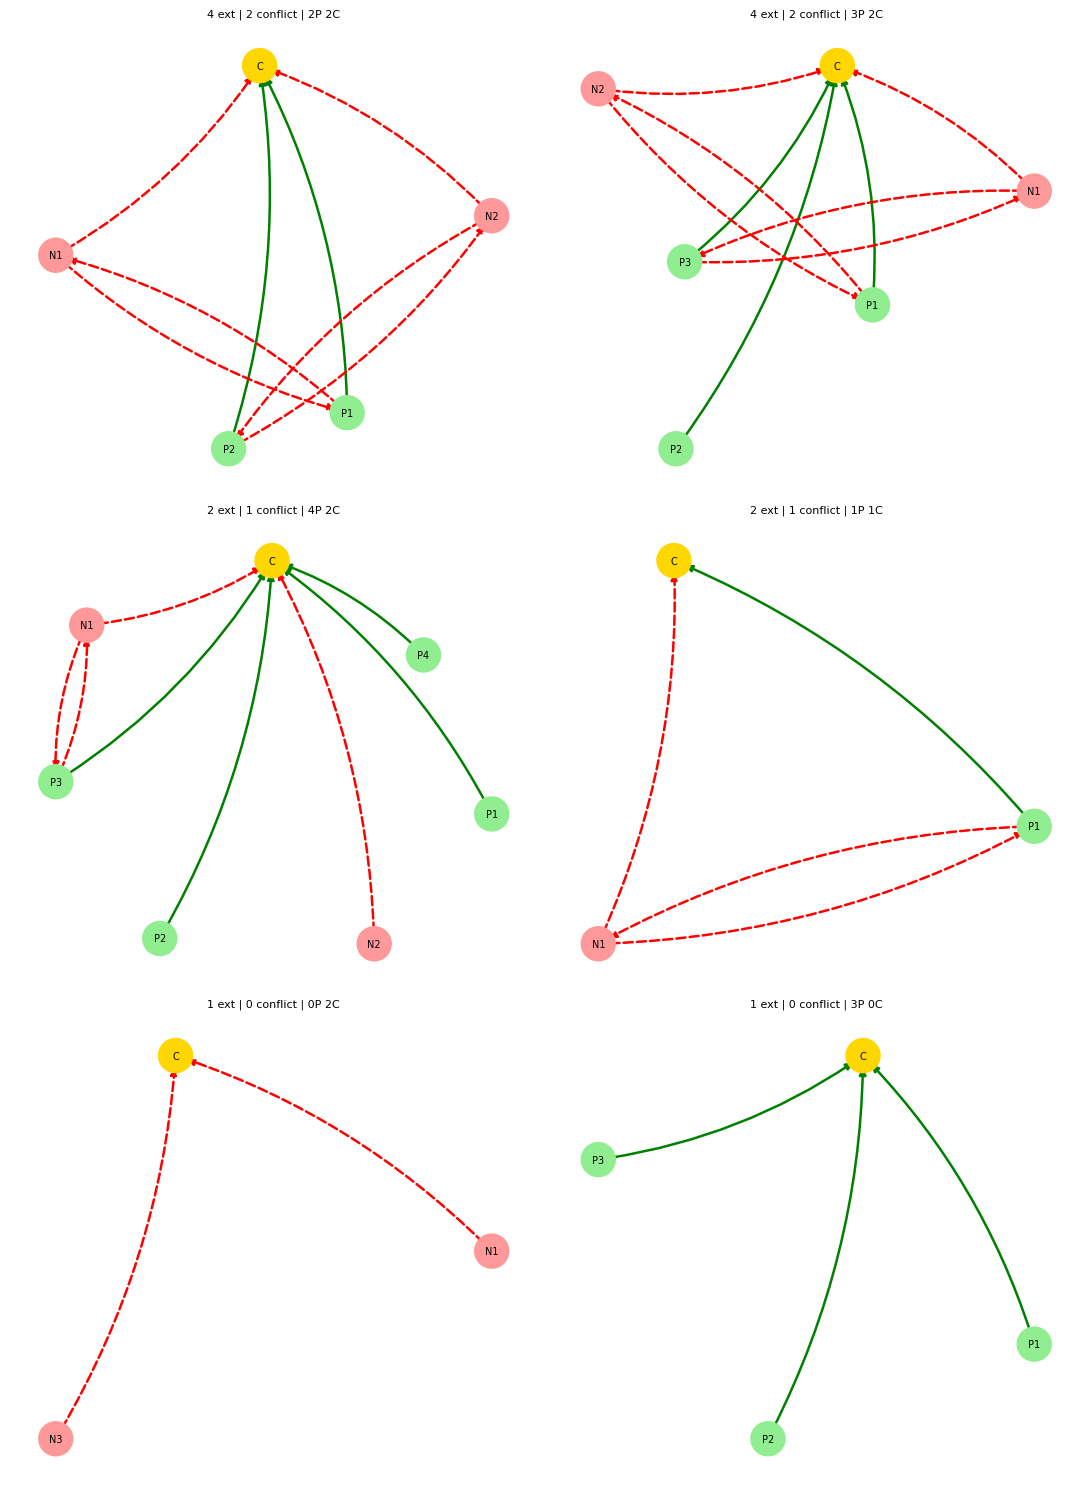

Yellow=CLAIM green=PRO red=CON | Row1: 4-ext, Row2: 2-ext, Row3: 1-ext


In [16]:
import matplotlib.pyplot as plt
import networkx as nx
results = [load_ck()[k] for k in sorted(load_ck())]

four_ext = [r for r in results if len(r["preferred_extensions"])==4]
two_ext = [r for r in results if len(r["preferred_extensions"])==2]
one_ext = [r for r in results if len(r["preferred_extensions"])==1]
print(f"4-ext: {len(four_ext)} | 2-ext: {len(two_ext)} | 1-ext: {len(one_ext)}")

def draw_graph(r, ax):
    G=nx.DiGraph(); colors=[]
    for nid in r["nodes"]:
        G.add_node(nid); colors.append("#FFD700" if nid=="CLAIM" else "#90EE90" if nid.startswith("P") else "#FF9999")
    sup=[tuple(e) for e in r["supports"]]; att=[tuple(e) for e in r["effective_attacks"]]
    G.add_edges_from(sup); G.add_edges_from(att)
    pos=nx.spring_layout(G, seed=42, k=1.8)
    nx.draw_networkx_nodes(G,pos,node_color=colors,node_size=600,ax=ax)
    nx.draw_networkx_labels(G,pos,{nd:nd.replace("CLAIM","C") for nd in G.nodes},font_size=7,ax=ax)
    nx.draw_networkx_edges(G,pos,edgelist=sup,edge_color="green",width=1.8,arrows=True,ax=ax,connectionstyle="arc3,rad=0.12")
    nx.draw_networkx_edges(G,pos,edgelist=att,edge_color="red",width=1.8,style="dashed",arrows=True,ax=ax,connectionstyle="arc3,rad=0.12")
    npro=sum(1 for nd in r["nodes"] if nd.startswith("P")); ncon=sum(1 for nd in r["nodes"] if nd.startswith("N"))
    cp=len(r.get("selected_conflict_pairs",[]))
    ax.set_title(f"{len(r['preferred_extensions'])} ext | {cp} conflict | {npro}P {ncon}C",fontsize=8); ax.axis("off")

show = four_ext[:2] + two_ext[:2] + one_ext[:2]
fig, axes = plt.subplots(3, 2, figsize=(11, 15))
for i in range(6):
    ax=axes[i//2][i%2]
    if i<len(show): draw_graph(show[i], ax)
    else: ax.axis("off")
plt.tight_layout(); plt.savefig("/kaggle/working/cosmos_graphs.png",dpi=100,bbox_inches="tight"); plt.show()
print("Yellow=CLAIM green=PRO red=CON | Row1: 4-ext, Row2: 2-ext, Row3: 1-ext")

In [12]:
CKPT = WORK_DIR / "cosmos_ckpt.pkl"
def load_ck(): return pickle.load(open(CKPT,"rb")) if CKPT.exists() else {}
def save_ck(d): pickle.dump(d, open(CKPT,"wb"))
def run_batch(n=100):
    done = load_ck()
    todo = [i for i in range(len(baf_df)) if i not in done][:n]
    print(f"Have {len(done)}/{len(baf_df)}. Running {len(todo)}...")
    for k, idx in enumerate(todo, 1):
        row = baf_df.iloc[idx].copy()
        try:
            row["facts_text"] = generate_facts(row["claim"])
            res = run_v3_baf_example(row)
        except Exception as e:
            print(f"error at {idx}: {str(e)[:50]}"); continue
        d = load_ck(); d[idx] = res; save_ck(d)
        if k % 10 == 0 or k == len(todo):
            cur = load_ck()
            acc = np.mean([cur[i]["preferred_decisions"]["credulous"]==cur[i]["gold"] for i in cur])
            print(f"  {k}/{len(todo)} → {len(cur)} total | running acc {acc*100:.1f}%")
    print(f"✅ {len(load_ck())}/{len(baf_df)} done")
print("✅ runner ready")

✅ runner ready


In [13]:
import glob
hits = glob.glob("/kaggle/input/**/cosmos_200.pkl", recursive=True)
print("found:", hits)
data = pickle.load(open(hits[0], "rb"))
restored = {r["example_index"]: r for r in data}
save_ck(restored)
print(f"Restored {len(load_ck())} examples")   # should say 200

found: ['/kaggle/input/cosmos-200-backup/cosmos_200.pkl']
Restored 200 examples


In [14]:
run_batch(100)   # → 300

Have 200/500. Running 100...
  10/100 → 210 total | running acc 64.3%
  20/100 → 220 total | running acc 63.2%
  30/100 → 230 total | running acc 63.0%
  40/100 → 240 total | running acc 63.3%
  50/100 → 250 total | running acc 62.8%
  60/100 → 260 total | running acc 63.1%
  70/100 → 270 total | running acc 63.0%
  80/100 → 280 total | running acc 63.2%
  90/100 → 290 total | running acc 63.1%
  100/100 → 300 total | running acc 62.3%
✅ 300/500 done


In [15]:
results = [load_ck()[k] for k in sorted(load_ck())]
gold = [r["gold"] for r in results]
n = len(results)
from collections import Counter
def net_support_pred(r): return int(len(r["supports"]) >= sum(1 for (s,t) in r["effective_attacks"] if t=="CLAIM"))
def no_objection_pred(r, ek):
    exts=r[ek]
    if not exts: return 0
    eff=set(map(tuple,r["effective_attacks"]))
    for ext in exts:
        es=set(ext)
        if "CLAIM" in es and not any(t=="CLAIM" and s in es for (s,t) in eff): return 1
    return 0
def mrow(name, pred):
    tn,fp,fn,tp=confusion_matrix(gold,pred,labels=[0,1]).ravel()
    return {"method":name,"accuracy":round(accuracy_score(gold,pred)*100,1),"precision":round(precision_score(gold,pred,zero_division=0)*100,1),"recall":round(recall_score(gold,pred,zero_division=0)*100,1),"f1":round(f1_score(gold,pred,zero_division=0)*100,1),"TN":tn,"FP":fp,"FN":fn,"TP":tp}
rows=[]
for rule in ["credulous","skeptical","majority"]:
    rows.append(mrow(f"preferred_{rule}",[r["preferred_decisions"][rule] for r in results]))
rows.append(mrow("preferred_no_objection",[no_objection_pred(r,"preferred_extensions") for r in results]))
for rule in ["credulous","skeptical","majority"]:
    rows.append(mrow(f"stable_{rule}",[r["stable_decisions"][rule] for r in results]))
rows.append(mrow("stable_no_objection",[no_objection_pred(r,"stable_extensions") for r in results]))
rows.append(mrow("net_support",[net_support_pred(r) for r in results]))
table=pd.DataFrame(rows).sort_values("accuracy",ascending=False).reset_index(drop=True)
pd.set_option("display.max_columns",None); pd.set_option("display.width",220)
print(f"=== DeepSeek CosmosQA extension — ALL semantics ({n}) ===\n"); print(table.to_string())
print(f"\nextension counts: {dict(sorted(Counter(len(r['preferred_extensions']) for r in results).items()))}")
print(f"gold balance: True={sum(gold)} False={n-sum(gold)}")

import base64, zipfile
from IPython.display import HTML, display
data=[load_ck()[k] for k in sorted(load_ck())]
N=len(data); pkl=WORK_DIR/f"cosmos_{N}.pkl"; pickle.dump(data,open(pkl,"wb"))
zp=WORK_DIR/f"cosmos_{N}_backup.zip"
with zipfile.ZipFile(zp,"w",zipfile.ZIP_DEFLATED) as z: z.write(pkl,arcname=f"cosmos_{N}.pkl")
b64=base64.b64encode(open(zp,"rb").read()).decode()
display(HTML(f'<a download="cosmos_{N}_backup.zip" href="data:application/zip;base64,{b64}" style="display:inline-block;padding:12px 20px;background:#2e7d32;color:white;border-radius:6px;text-decoration:none;font-weight:bold;">⬇ Download cosmos_{N}_backup.zip</a>'))
print(f"Backed up {N}")

=== DeepSeek CosmosQA extension — ALL semantics (300) ===

                   method  accuracy  precision  recall    f1  TN   FP  FN   TP
0     preferred_skeptical      65.7       60.6    89.3  72.2  63   87  16  134
1        stable_skeptical      65.7       60.6    89.3  72.2  63   87  16  134
2         stable_majority      64.0       59.2    90.0  71.4  57   93  15  135
3      preferred_majority      64.0       59.2    90.0  71.4  57   93  15  135
4     preferred_credulous      62.3       57.9    90.7  70.6  51   99  14  136
5        stable_credulous      62.3       57.9    90.7  70.6  51   99  14  136
6  preferred_no_objection      62.3       57.9    90.7  70.6  51   99  14  136
7     stable_no_objection      62.3       57.9    90.7  70.6  51   99  14  136
8             net_support      57.7       54.2    99.3  70.1  24  126   1  149

extension counts: {1: 281, 2: 12, 4: 7}
gold balance: True=150 False=150


Backed up 300


In [16]:
run_batch(100) 

Have 300/500. Running 100...
  10/100 → 310 total | running acc 62.9%
  20/100 → 320 total | running acc 62.5%
  30/100 → 330 total | running acc 63.0%
  40/100 → 340 total | running acc 63.8%
  50/100 → 350 total | running acc 63.4%
  60/100 → 360 total | running acc 63.6%
  70/100 → 370 total | running acc 63.5%
  80/100 → 380 total | running acc 63.9%
  90/100 → 390 total | running acc 64.1%
  100/100 → 400 total | running acc 63.5%
✅ 400/500 done


In [17]:
results = [load_ck()[k] for k in sorted(load_ck())]
gold = [r["gold"] for r in results]
n = len(results)
from collections import Counter
def net_support_pred(r): return int(len(r["supports"]) >= sum(1 for (s,t) in r["effective_attacks"] if t=="CLAIM"))
def no_objection_pred(r, ek):
    exts=r[ek]
    if not exts: return 0
    eff=set(map(tuple,r["effective_attacks"]))
    for ext in exts:
        es=set(ext)
        if "CLAIM" in es and not any(t=="CLAIM" and s in es for (s,t) in eff): return 1
    return 0
def mrow(name, pred):
    tn,fp,fn,tp=confusion_matrix(gold,pred,labels=[0,1]).ravel()
    return {"method":name,"accuracy":round(accuracy_score(gold,pred)*100,1),"precision":round(precision_score(gold,pred,zero_division=0)*100,1),"recall":round(recall_score(gold,pred,zero_division=0)*100,1),"f1":round(f1_score(gold,pred,zero_division=0)*100,1),"TN":tn,"FP":fp,"FN":fn,"TP":tp}
rows=[]
for rule in ["credulous","skeptical","majority"]:
    rows.append(mrow(f"preferred_{rule}",[r["preferred_decisions"][rule] for r in results]))
rows.append(mrow("preferred_no_objection",[no_objection_pred(r,"preferred_extensions") for r in results]))
for rule in ["credulous","skeptical","majority"]:
    rows.append(mrow(f"stable_{rule}",[r["stable_decisions"][rule] for r in results]))
rows.append(mrow("stable_no_objection",[no_objection_pred(r,"stable_extensions") for r in results]))
rows.append(mrow("net_support",[net_support_pred(r) for r in results]))
table=pd.DataFrame(rows).sort_values("accuracy",ascending=False).reset_index(drop=True)
pd.set_option("display.max_columns",None); pd.set_option("display.width",220)
print(f"=== DeepSeek CosmosQA extension — ALL semantics ({n}) ===\n"); print(table.to_string())
print(f"\nextension counts: {dict(sorted(Counter(len(r['preferred_extensions']) for r in results).items()))}")
print(f"gold balance: True={sum(gold)} False={n-sum(gold)}")

import base64, zipfile
from IPython.display import HTML, display
data=[load_ck()[k] for k in sorted(load_ck())]
N=len(data); pkl=WORK_DIR/f"cosmos_{N}.pkl"; pickle.dump(data,open(pkl,"wb"))
zp=WORK_DIR/f"cosmos_{N}_backup.zip"
with zipfile.ZipFile(zp,"w",zipfile.ZIP_DEFLATED) as z: z.write(pkl,arcname=f"cosmos_{N}.pkl")
b64=base64.b64encode(open(zp,"rb").read()).decode()
display(HTML(f'<a download="cosmos_{N}_backup.zip" href="data:application/zip;base64,{b64}" style="display:inline-block;padding:12px 20px;background:#2e7d32;color:white;border-radius:6px;text-decoration:none;font-weight:bold;">⬇ Download cosmos_{N}_backup.zip</a>'))
print(f"Backed up {N}")

=== DeepSeek CosmosQA extension — ALL semantics (400) ===

                   method  accuracy  precision  recall    f1  TN   FP  FN   TP
0     preferred_skeptical      66.2       61.9    88.8  72.9  83  112  23  182
1        stable_skeptical      66.2       61.9    88.8  72.9  83  112  23  182
2         stable_majority      64.8       60.5    89.8  72.3  75  120  21  184
3      preferred_majority      64.8       60.5    89.8  72.3  75  120  21  184
4     preferred_credulous      63.5       59.5    90.2  71.7  69  126  20  185
5        stable_credulous      63.5       59.5    90.2  71.7  69  126  20  185
6  preferred_no_objection      63.5       59.5    90.2  71.7  69  126  20  185
7     stable_no_objection      63.5       59.5    90.2  71.7  69  126  20  185
8             net_support      59.0       55.6    99.5  71.3  32  163   1  204

extension counts: {1: 374, 2: 19, 4: 7}
gold balance: True=205 False=195


Backed up 400


In [18]:
run_batch(100) 

Have 400/500. Running 100...
  10/100 → 410 total | running acc 62.9%
  20/100 → 420 total | running acc 62.9%
  30/100 → 430 total | running acc 63.3%
  40/100 → 440 total | running acc 63.4%
  50/100 → 450 total | running acc 63.3%
  60/100 → 460 total | running acc 63.5%
  70/100 → 470 total | running acc 63.6%
  80/100 → 480 total | running acc 63.3%
  90/100 → 490 total | running acc 63.5%
  100/100 → 500 total | running acc 64.0%
✅ 500/500 done


In [19]:
results = [load_ck()[k] for k in sorted(load_ck())]
gold = [r["gold"] for r in results]
n = len(results)
from collections import Counter
def net_support_pred(r): return int(len(r["supports"]) >= sum(1 for (s,t) in r["effective_attacks"] if t=="CLAIM"))
def no_objection_pred(r, ek):
    exts=r[ek]
    if not exts: return 0
    eff=set(map(tuple,r["effective_attacks"]))
    for ext in exts:
        es=set(ext)
        if "CLAIM" in es and not any(t=="CLAIM" and s in es for (s,t) in eff): return 1
    return 0
def mrow(name, pred):
    tn,fp,fn,tp=confusion_matrix(gold,pred,labels=[0,1]).ravel()
    return {"method":name,"accuracy":round(accuracy_score(gold,pred)*100,1),"precision":round(precision_score(gold,pred,zero_division=0)*100,1),"recall":round(recall_score(gold,pred,zero_division=0)*100,1),"f1":round(f1_score(gold,pred,zero_division=0)*100,1),"TN":tn,"FP":fp,"FN":fn,"TP":tp}
rows=[]
for rule in ["credulous","skeptical","majority"]:
    rows.append(mrow(f"preferred_{rule}",[r["preferred_decisions"][rule] for r in results]))
rows.append(mrow("preferred_no_objection",[no_objection_pred(r,"preferred_extensions") for r in results]))
for rule in ["credulous","skeptical","majority"]:
    rows.append(mrow(f"stable_{rule}",[r["stable_decisions"][rule] for r in results]))
rows.append(mrow("stable_no_objection",[no_objection_pred(r,"stable_extensions") for r in results]))
rows.append(mrow("net_support",[net_support_pred(r) for r in results]))
table=pd.DataFrame(rows).sort_values("accuracy",ascending=False).reset_index(drop=True)
pd.set_option("display.max_columns",None); pd.set_option("display.width",220)
print(f"=== DeepSeek CosmosQA extension — ALL semantics ({n}) ===\n"); print(table.to_string())
print(f"gold balance: True={sum(gold)} False={n-sum(gold)}")

import base64, zipfile
from IPython.display import HTML, display
data=[load_ck()[k] for k in sorted(load_ck())]
N=len(data); pkl=WORK_DIR/f"cosmos_{N}.pkl"; pickle.dump(data,open(pkl,"wb"))
zp=WORK_DIR/f"cosmos_{N}_backup.zip"
with zipfile.ZipFile(zp,"w",zipfile.ZIP_DEFLATED) as z: z.write(pkl,arcname=f"cosmos_{N}.pkl")
b64=base64.b64encode(open(zp,"rb").read()).decode()
display(HTML(f'<a download="cosmos_{N}_backup.zip" href="data:application/zip;base64,{b64}" style="display:inline-block;padding:12px 20px;background:#2e7d32;color:white;border-radius:6px;text-decoration:none;font-weight:bold;">⬇ Download cosmos_{N}_backup.zip</a>'))
print(f"Backed up {N}")

=== DeepSeek CosmosQA extension — ALL semantics (500) ===

                   method  accuracy  precision  recall    f1   TN   FP  FN   TP
0     preferred_skeptical      66.6       61.4    89.2  72.8  110  140  27  223
1        stable_skeptical      66.6       61.4    89.2  72.8  110  140  27  223
2         stable_majority      64.8       59.8    90.0  71.9   99  151  25  225
3      preferred_majority      64.8       59.8    90.0  71.9   99  151  25  225
4     preferred_credulous      64.0       59.1    90.8  71.6   93  157  23  227
5        stable_credulous      64.0       59.1    90.8  71.6   93  157  23  227
6  preferred_no_objection      64.0       59.1    90.8  71.6   93  157  23  227
7     stable_no_objection      64.0       59.1    90.8  71.6   93  157  23  227
8             net_support      58.0       54.4    98.8  70.2   43  207   3  247
gold balance: True=250 False=250


Backed up 500


In [20]:
results = [load_ck()[k] for k in sorted(load_ck())]
n = len(results)
from collections import Counter
print(f"=== DeepSeek CosmosQA — Extension Statistics ({n}) ===\n")
pref_counts = Counter(len(r["preferred_extensions"]) for r in results)
print("PREFERRED extensions per example:")
for k in sorted(pref_counts):
    print(f"  {k} extension(s): {pref_counts[k]:3d} ({pref_counts[k]/n*100:.1f}%)")
print(f"  → avg: {np.mean([len(r['preferred_extensions']) for r in results]):.2f} | max: {max(len(r['preferred_extensions']) for r in results)}")
cp_counts = Counter(len(r.get("selected_conflict_pairs",[])) for r in results)
print("\nConflict pairs per example (n → 2^n ext):")
for k in sorted(cp_counts):
    print(f"  {k} pair(s): {cp_counts[k]:3d} ({cp_counts[k]/n*100:.1f}%) → expect {2**k} ext")
con_counts = Counter(sum(1 for nid in r["nodes"] if nid.startswith("N")) for r in results)
print("\nCON kept per example:")
for k in sorted(con_counts):
    print(f"  {k} CON: {con_counts[k]:3d} ({con_counts[k]/n*100:.1f}%)")
print(f"\nAvg supports: {np.mean([len(r['supports']) for r in results]):.2f} | Avg attacks: {np.mean([len(r['effective_attacks']) for r in results]):.2f}")
multi = sum(1 for r in results if len(r["preferred_extensions"]) > 1)
zero_con = sum(1 for r in results if sum(1 for nid in r["nodes"] if nid.startswith("N"))==0)
print(f"Multiple extensions: {multi} ({multi/n*100:.1f}%) | Zero-CON: {zero_con} ({zero_con/n*100:.1f}%)")

=== DeepSeek CosmosQA — Extension Statistics (500) ===

PREFERRED extensions per example:
  1 extension(s): 466 (93.2%)
  2 extension(s):  26 (5.2%)
  4 extension(s):   8 (1.6%)
  → avg: 1.10 | max: 4

Conflict pairs per example (n → 2^n ext):
  0 pair(s): 466 (93.2%) → expect 1 ext
  1 pair(s):  26 (5.2%) → expect 2 ext
  2 pair(s):   8 (1.6%) → expect 4 ext

CON kept per example:
  0 CON: 363 (72.6%)
  1 CON:  61 (12.2%)
  2 CON:  76 (15.2%)

Avg supports: 2.77 | Avg attacks: 0.59
Multiple extensions: 34 (6.8%) | Zero-CON: 363 (72.6%)


In [21]:
results = [load_ck()[k] for k in sorted(load_ck())]
four_ext = [r for r in results if len(r["preferred_extensions"])==4]
two_ext  = [r for r in results if len(r["preferred_extensions"])==2]
one_ext  = [r for r in results if len(r["preferred_extensions"])==1]
tp=[r for r in one_ext if r["gold"]==1 and r["preferred_decisions"]["credulous"]==1]
tn=[r for r in one_ext if r["gold"]==0 and r["preferred_decisions"]["credulous"]==0]
fp=[r for r in one_ext if r["gold"]==0 and r["preferred_decisions"]["credulous"]==1]

show = four_ext[:3] + two_ext[:3] + tp[:1] + tn[:1] + fp[:2]
show = show[:10]

for i, r in enumerate(show, 1):
    gold="TRUE" if r["gold"]==1 else "FALSE"
    cred="TRUE" if r["preferred_decisions"]["credulous"]==1 else "FALSE"
    skep="TRUE" if r["preferred_decisions"]["skeptical"]==1 else "FALSE"
    mark="✓" if r["gold"]==r["preferred_decisions"]["credulous"] else "✗"
    print("="*90)
    print(f"[{i}] {len(r['preferred_extensions'])} EXTENSION(S) | GOLD={gold} | cred={cred} skep={skep} {mark}")
    print(f"CLAIM: {r['claim'][:150]}")
    print("PRO arguments:")
    for nid in sorted(r["nodes"]):
        if nid.startswith("P"): print(f"   {nid}: {r['nodes'][nid]['text'][:80]}")
    print("CON arguments:")
    cons=[nid for nid in sorted(r["nodes"]) if nid.startswith("N")]
    if cons:
        for nid in cons: print(f"   {nid}: {r['nodes'][nid]['text'][:80]}")
    else: print("   (none)")
    print(f"conflict pairs: {[(p['pro'],p['con']) for p in r.get('selected_conflict_pairs',[])]}")
    for j, ext in enumerate(r["preferred_extensions"], 1):
        print(f"   Ext{j}: {sorted(ext)} {'[CLAIM in → TRUE]' if 'CLAIM' in ext else '[CLAIM out → FALSE]'}")
    print()

[1] 4 EXTENSION(S) | GOLD=FALSE | cred=TRUE skep=FALSE ✗
CLAIM: The reason we ca n't get it to pass inspection is because it 's crazy . When you flip on the right blinker the radio light blinks , when you hit the b
PRO arguments:
   P1: The symptoms (blinker affecting radio light, brake affecting backup lights, head
   P2: A faulty headlight switch can cause cross-circuiting, leading to the described i
CON arguments:
   N1: The claim's fix of buying new lights is insufficient because the symptoms point 
   N2: The claim incorrectly identifies the cause as 'crazy' and suggests a simple fix,
conflict pairs: [('P1', 'N1'), ('P2', 'N2')]
   Ext1: ['N1', 'N2'] [CLAIM out → FALSE]
   Ext2: ['N1', 'P2'] [CLAIM out → FALSE]
   Ext3: ['N2', 'P1'] [CLAIM out → FALSE]
   Ext4: ['CLAIM', 'P1', 'P2'] [CLAIM in → TRUE]

[2] 4 EXTENSION(S) | GOLD=FALSE | cred=TRUE skep=FALSE ✗
CLAIM: I am hallucinating , he thought . Slowly , with great caution , the creature broke the surface . He was , Atobe realis

4-ext:8 2-ext:26 1-ext:466 | showing 10


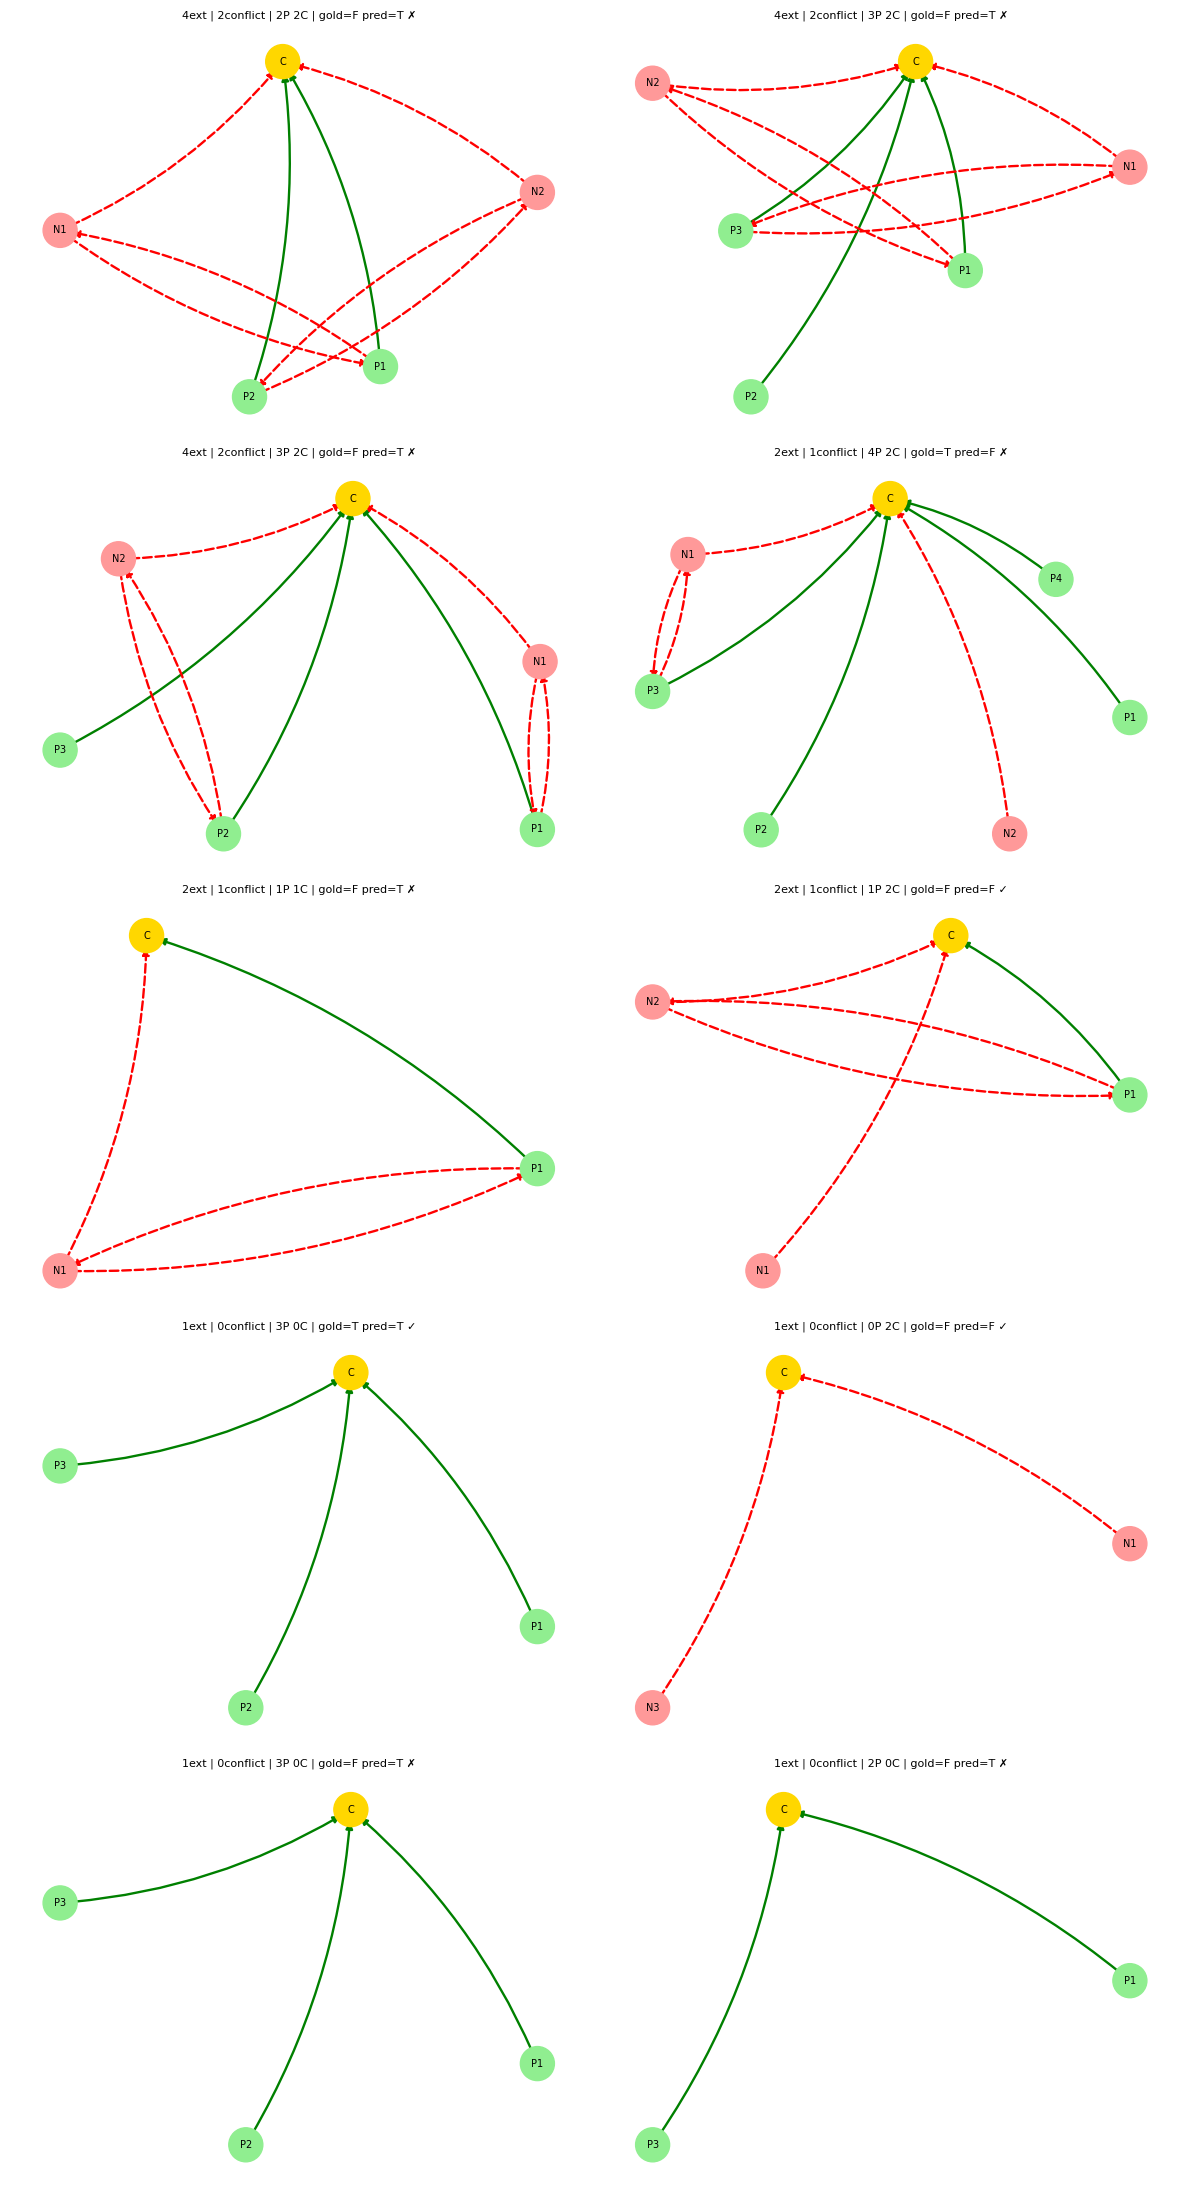

Yellow=CLAIM green=PRO red=CON | green=support, red dashed=attack

[1] 4 EXTENSION(S) | GOLD=FALSE | credulous=TRUE skeptical=FALSE | ✗ wrong
CLAIM: The reason we ca n't get it to pass inspection is because it 's crazy . When you flip on the right blinker the radio light blinks , when you hit the b
PRO:
   P1: The symptoms (blinker affecting radio light, brake affecting backup lights, head
   P2: A faulty headlight switch can cause cross-circuiting, leading to the described i
CON:
   N1: The claim's fix of buying new lights is insufficient because the symptoms point 
   N2: The claim incorrectly identifies the cause as 'crazy' and suggests a simple fix,
conflict pairs: [('P1', 'N1'), ('P2', 'N2')]
   Ext1: ['N1', 'N2'] [CLAIM out → FALSE]
   Ext2: ['N1', 'P2'] [CLAIM out → FALSE]
   Ext3: ['N2', 'P1'] [CLAIM out → FALSE]
   Ext4: ['CLAIM', 'P1', 'P2'] [CLAIM in → TRUE]

[2] 4 EXTENSION(S) | GOLD=FALSE | credulous=TRUE skeptical=FALSE | ✗ wrong
CLAIM: I am hallucinating , he thought . S

In [22]:
import matplotlib.pyplot as plt
import networkx as nx

results = [load_ck()[k] for k in sorted(load_ck())]
four_ext = [r for r in results if len(r["preferred_extensions"])==4]
two_ext  = [r for r in results if len(r["preferred_extensions"])==2]
one_ext  = [r for r in results if len(r["preferred_extensions"])==1]
tp=[r for r in one_ext if r["gold"]==1 and r["preferred_decisions"]["credulous"]==1]
tn=[r for r in one_ext if r["gold"]==0 and r["preferred_decisions"]["credulous"]==0]
fp=[r for r in one_ext if r["gold"]==0 and r["preferred_decisions"]["credulous"]==1]
show = (four_ext[:3] + two_ext[:3] + tp[:1] + tn[:1] + fp[:2])[:10]
print(f"4-ext:{len(four_ext)} 2-ext:{len(two_ext)} 1-ext:{len(one_ext)} | showing {len(show)}")

def draw_graph(r, ax):
    G=nx.DiGraph(); colors=[]
    for nid in r["nodes"]:
        G.add_node(nid)
        colors.append("#FFD700" if nid=="CLAIM" else "#90EE90" if nid.startswith("P") else "#FF9999")
    sup=[tuple(e) for e in r["supports"]]; att=[tuple(e) for e in r["effective_attacks"]]
    G.add_edges_from(sup); G.add_edges_from(att)
    pos=nx.spring_layout(G, seed=42, k=1.9)
    nx.draw_networkx_nodes(G,pos,node_color=colors,node_size=600,ax=ax)
    nx.draw_networkx_labels(G,pos,{nd:nd.replace("CLAIM","C") for nd in G.nodes},font_size=7,ax=ax)
    nx.draw_networkx_edges(G,pos,edgelist=sup,edge_color="green",width=1.7,arrows=True,ax=ax,connectionstyle="arc3,rad=0.12")
    nx.draw_networkx_edges(G,pos,edgelist=att,edge_color="red",width=1.7,style="dashed",arrows=True,ax=ax,connectionstyle="arc3,rad=0.12")
    gold="T" if r["gold"]==1 else "F"; pred="T" if r["preferred_decisions"]["credulous"]==1 else "F"
    mark="✓" if gold==pred else "✗"
    npro=sum(1 for nd in r["nodes"] if nd.startswith("P")); ncon=sum(1 for nd in r["nodes"] if nd.startswith("N"))
    cp=len(r.get("selected_conflict_pairs",[]))
    ax.set_title(f"{len(r['preferred_extensions'])}ext | {cp}conflict | {npro}P {ncon}C | gold={gold} pred={pred} {mark}",fontsize=8)
    ax.axis("off")

fig, axes = plt.subplots(5, 2, figsize=(12, 22))
for i in range(10):
    ax=axes[i//2][i%2]
    if i<len(show): draw_graph(show[i], ax)
    else: ax.axis("off")
plt.tight_layout(); plt.savefig("/kaggle/working/cosmos_10graphs.png",dpi=90,bbox_inches="tight"); plt.show()
print("Yellow=CLAIM green=PRO red=CON | green=support, red dashed=attack\n")

# details below each
for i, r in enumerate(show, 1):
    gold="TRUE" if r["gold"]==1 else "FALSE"
    cred="TRUE" if r["preferred_decisions"]["credulous"]==1 else "FALSE"
    skep="TRUE" if r["preferred_decisions"]["skeptical"]==1 else "FALSE"
    mark="✓ correct" if r["gold"]==r["preferred_decisions"]["credulous"] else "✗ wrong"
    print("="*90)
    print(f"[{i}] {len(r['preferred_extensions'])} EXTENSION(S) | GOLD={gold} | credulous={cred} skeptical={skep} | {mark}")
    print(f"CLAIM: {r['claim'][:150]}")
    print("PRO:")
    for nid in sorted(r["nodes"]):
        if nid.startswith("P"): print(f"   {nid}: {r['nodes'][nid]['text'][:80]}")
    cons=[nid for nid in sorted(r["nodes"]) if nid.startswith("N")]
    print("CON:" if cons else "CON: (none)")
    for nid in cons: print(f"   {nid}: {r['nodes'][nid]['text'][:80]}")
    print(f"conflict pairs: {[(p['pro'],p['con']) for p in r.get('selected_conflict_pairs',[])]}")
    for j, ext in enumerate(r["preferred_extensions"], 1):
        print(f"   Ext{j}: {sorted(ext)} {'[CLAIM in → TRUE]' if 'CLAIM' in ext else '[CLAIM out → FALSE]'}")
    print()

In [ ]:
# ===== RECOMPUTE DECISION RULES (no API calls) =====
# It reloads the saved frameworks and recomputes every decision rule with the
# definitions used in the paper:
#   majority     : claim in STRICTLY more than half of the extensions
#   No-objection : claim in at least one extension AND no attacker of the claim
#                  (direct or derived) in any extension
#   grounded     : least fixed point of the characteristic function
import pickle, glob
from pathlib import Path
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# load the saved frameworks (results/per_claim/deepseek_cosmosqa_500.pkl in the repository,
# or the checkpoint of the run above if it is still there)
ck = Path("/kaggle/working/cosmos_ext/cosmos_ckpt.pkl")
if ck.exists():
    d = pickle.load(open(ck, "rb")); results = [d[k] for k in sorted(d)]
else:
    results = pickle.load(open("../results/per_claim/deepseek_cosmosqa_500.pkl", "rb"))
print("frameworks loaded:", len(results))

def grounded(args, att):
    att = set(map(tuple, att)); g = set()
    while True:
        new = {a for a in args
               if all(any((y, x) in att for y in g) for (x, t) in att if t == a)}
        if new == g: return g
        g = new

def rules(r):
    exts = [set(e) for e in r["preferred_extensions"]]
    att = [tuple(e) for e in r["effective_attacks"]]
    cc = sum("CLAIM" in e for e in exts); m = len(exts)
    attackers = {s for s, t in att if t == "CLAIM"}
    in_any = set().union(*exts) if exts else set()
    return {"credulous": int(cc >= 1),
            "skeptical": int(m > 0 and cc == m),
            "majority": int(cc * 2 > m),
            "no_objection": int(cc >= 1 and not (attackers & in_any)),
            "grounded": int("CLAIM" in grounded(set(r["nodes"]), att))}

gold = [r["gold"] for r in results]
preds = {k: [] for k in ["credulous", "no_objection", "majority", "skeptical", "grounded"]}
for r in results:
    x = rules(r)
    for k in preds: preds[k].append(x[k])

rows = []
for k, p in preds.items():
    tn, fp, fn, tp = confusion_matrix(gold, p, labels=[0, 1]).ravel()
    rows.append({"rule": k, "acc": round(accuracy_score(gold, p)*100, 1),
                 "prec": round(precision_score(gold, p, zero_division=0)*100, 1),
                 "rec": round(recall_score(gold, p, zero_division=0)*100, 1),
                 "f1": round(f1_score(gold, p, zero_division=0)*100, 1),
                 "TN": tn, "FP": fp, "FN": fn, "TP": tp})
print(pd.DataFrame(rows).to_string(index=False))
same = all(preds["skeptical"] == preds[k] for k in ["majority", "no_objection", "grounded"])
print("\nskeptical = majority = No-objection = grounded on every claim:", same)


frameworks loaded: 500
        rule  acc  prec  rec   f1  TN  FP  FN  TP
   credulous 64.0  59.1 90.8 71.6  93 157  23 227
no_objection 66.6  61.4 89.2 72.8 110 140  27 223
    majority 66.6  61.4 89.2 72.8 110 140  27 223
   skeptical 66.6  61.4 89.2 72.8 110 140  27 223
    grounded 66.6  61.4 89.2 72.8 110 140  27 223

skeptical = majority = No-objection = grounded on every claim: True
